In [61]:
from shapely.geometry import Polygon, Point
import shapely
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.spatial import Voronoi, voronoi_plot_2d

from artistic_pattern_gen import generate_points, points_on_polygon_boundary, cell_polygons, compare_points, goal_generation, create_rectangle, create_circle, create_triangle

In [68]:
# Create a triangle
#triangle_vertices = [(1.5, -2.5), (4.5, -2.5), (3, 1)]
#polygon = create_triangle(triangle_vertices)

polygon = create_circle((-1.5, -1.5), 1.0)

In [69]:
# generate random points in polygon
n = 2
points = generate_points(n, polygon)
points = np.array([[point.x, point.y] for point in points])

In [70]:
buffer = polygon.buffer(2)
boundary = polygon.buffer(10)
    
# generate points on the boundary of a giant rectangle around the polygon
boundary_points = points_on_polygon_boundary(buffer, 100)

# get all points in one array
all_points = np.vstack((boundary_points, points))

In [71]:
# compute voronoi
voronoi = Voronoi(all_points)

In [72]:
cells = []
for region in voronoi.regions:
    if len(region) > 1 and -1 not in region:
        vertices = [voronoi.vertices[i] for i in region]

        contained = True
        for vertice in vertices:
            if not boundary.contains(Point(vertice[0], vertice[1])):
                contained = False
        if contained:
            cells.append(polygon.intersection(Polygon(vertices)))

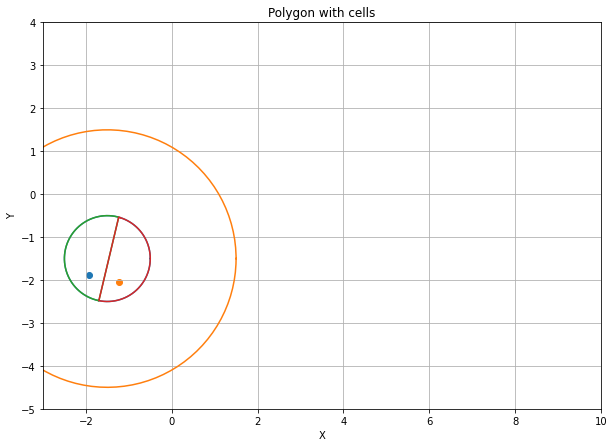

2


In [73]:
plt.figure(figsize=(10,10))
plt.plot(*polygon.exterior.xy)
plt.plot(*buffer.exterior.xy)

for point in points:
    plt.scatter(point[0], point[1])
    
for cell in cells:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.xlim([-3,10])
plt.ylim([-5,4])
plt.show()

print(len(cells))

In [ ]:
points = generate_points(n, polygon)
points = np.array([[point.x, point.y] for point in points])
old_centroids = None

i = True
while i:
    voronoi_polygons = cell_polygons(points, polygon)
    centroids = [shapely.centroid(cell) for cell in voronoi_polygons]
    points = np.array([[point.x, point.y] for point in centroids])

    if old_centroids is not None:
        if compare_points(points, old_centroids):
            i = False

    if i%10 == 0:
        print("Iteration: ", i)
    
    old_centroids = points